<a href="https://colab.research.google.com/github/solasobambo-prog/ts-data-science/blob/main/week5c.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## CONFIDENCE INTERVAL BY HAND

In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')

# Load the Movies dataset cleanly
path = kagglehub.dataset_download("danielgrijalvas/movies")
csv_file = next(f for f in os.listdir(path) if f.endswith('.csv'))
movies = pd.read_csv(os.path.join(path, csv_file))
raw_copy = movies.copy()

movies['gross_m'] = movies['gross'] / 1e6

def finish(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)

n_rows, n_cols = movies.shape
print(f"Loaded movies dataset: {n_rows:,} rows, {n_cols} columns")


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded movies dataset: 7,668 rows, 16 columns


In [2]:
print("=== STEPS 1 & 2: 95% CONFIDENCE INTERVAL BY HAND VS. SCIPY ===")

s = movies['score'].dropna()
n = len(s)
mean = float(s.mean())
sd = float(s.std(ddof=1))

# 1. Compute 95% CI by hand
se = sd / np.sqrt(n)
t_crit = float(stats.t.ppf(0.975, df=n - 1))
margin = t_crit * se
ci_low_hand = mean - margin
ci_high_hand = mean + margin

# 2. Verify against scipy.stats.t.interval
ci_low_scipy, ci_high_scipy = stats.t.interval(0.95, df=n - 1, loc=mean, scale=se)

print(f"IMDb Score (n = {n:,}) -> Mean: {mean:.4f} | SD: {sd:.4f} | SE: {se:.5f} | t_crit (df={n-1}): {t_crit:.4f}")
print(f"By-hand 95% CI: ({ci_low_hand:.4f}, {ci_high_hand:.4f}) | Width: {ci_high_hand - ci_low_hand:.4f}")
print(f"Scipy   95% CI: ({ci_low_scipy:.4f}, {ci_high_scipy:.4f}) | Max abs diff: {abs(ci_low_hand - ci_low_scipy):.2e}")

# Rubric summary sentence (using computed values):
rubric_sentence = f"Average IMDb score is {mean:.2f}, 95 percent CI from {ci_low_hand:.2f} to {ci_high_hand:.2f}, n = {n:,}."
print("\nRubric Summary Sentence:")
print(rubric_sentence)


=== STEPS 1 & 2: 95% CONFIDENCE INTERVAL BY HAND VS. SCIPY ===
IMDb Score (n = 7,665) -> Mean: 6.3904 | SD: 0.9688 | SE: 0.01107 | t_crit (df=7664): 1.9603
By-hand 95% CI: (6.3687, 6.4121) | Width: 0.0434
Scipy   95% CI: (6.3687, 6.4121) | Max abs diff: 0.00e+00

Rubric Summary Sentence:
Average IMDb score is 6.39, 95 percent CI from 6.37 to 6.41, n = 7,665.


=== STEPS 3 & 4: INTERVAL WIDTH VS. SAMPLE SIZE AND CONFIDENCE LEVEL ===

Step 3: Width vs. Sample Size (Narrowing factor from n=30 to n=3000: 8.52x):


,sample_size_n,sample_mean,se,t_crit,ci_95_low,ci_95_high,ci_width
0,30,6.410,0.1449,2.045,6.114,6.706,0.5927
1,300,6.340,0.0557,1.968,6.231,6.450,0.2191
2,3000,6.393,0.0178,1.961,6.358,6.428,0.0696



Step 4: Width vs. Confidence Level on Full Score Column (n = 7,665):


,confidence_level_pct,t_crit,ci_low,ci_high,ci_width
0,90,1.6451,6.3722,6.4086,0.0364
1,95,1.9603,6.3687,6.4121,0.0434
2,99,2.5765,6.3619,6.4189,0.0570


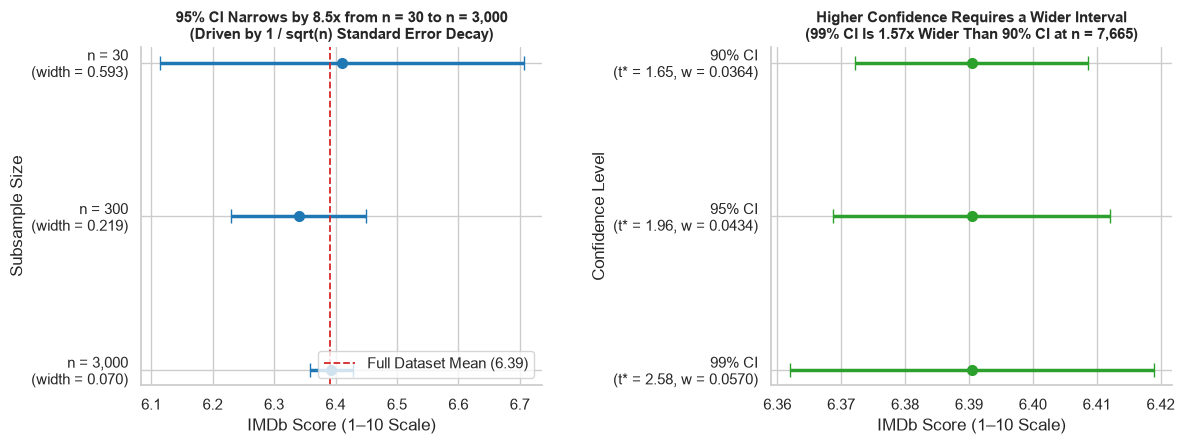

In [3]:
print("=== STEPS 3 & 4: INTERVAL WIDTH VS. SAMPLE SIZE AND CONFIDENCE LEVEL ===")

# --- ORIGINAL PREDICTION (STEP 3 — UNEDITED) ---
# Prediction (n = 30 to n = 3000 narrowing factor): Going from n = 30 to n = 3000 increases sample size by 100x, so standard error shrinks by sqrt(100) = 10x. Because the t critical value also drops slightly from t_0.975(29) ≈ 2.045 to t_0.975(2999) ≈ 1.961 (a ~1.043x factor), the total 95% CI width will narrow by a factor of roughly 10.4x (around 10x–10.5x).

rng_sub = np.random.default_rng(42)
sub_sizes = (30, 300, 3000)
width_n_rows = []

for sz in sub_sizes:
    sub = rng_sub.choice(s, size=sz, replace=False)
    m_sub = float(sub.mean())
    se_sub = float(sub.std(ddof=1)) / np.sqrt(sz)
    t_sub = float(stats.t.ppf(0.975, df=sz - 1))
    lo, hi = stats.t.interval(0.95, df=sz - 1, loc=m_sub, scale=se_sub)
    width_n_rows.append({
        'sample_size_n': sz,
        'sample_mean': round(m_sub, 3),
        'se': round(se_sub, 4),
        't_crit': round(t_sub, 3),
        'ci_95_low': round(float(lo), 3),
        'ci_95_high': round(float(hi), 3),
        'ci_width': round(float(hi - lo), 4)
    })

width_n_df = pd.DataFrame(width_n_rows)
w_30 = float(width_n_df.loc[width_n_df['sample_size_n'] == 30, 'ci_width'].squeeze())
w_3000 = float(width_n_df.loc[width_n_df['sample_size_n'] == 3000, 'ci_width'].squeeze())
narrow_factor = w_30 / w_3000

print(f"\nStep 3: Width vs. Sample Size (Narrowing factor from n=30 to n=3000: {narrow_factor:.2f}x):")
display(width_n_df)

# Step 4: Width vs. confidence level (90%, 95%, 99%) on the full column (n = 7,665)
conf_levels = (0.90, 0.95, 0.99)
width_c_rows = []
for cl in conf_levels:
    alpha_tail = 1 - (1 - cl) / 2
    t_cl = float(stats.t.ppf(alpha_tail, df=n - 1))
    lo, hi = stats.t.interval(cl, df=n - 1, loc=mean, scale=se)
    width_c_rows.append({
        'confidence_level_pct': int(round(cl * 100)),
        't_crit': round(t_cl, 4),
        'ci_low': round(float(lo), 4),
        'ci_high': round(float(hi), 4),
        'ci_width': round(float(hi - lo), 4)
    })

width_c_df = pd.DataFrame(width_c_rows)
print(f"\nStep 4: Width vs. Confidence Level on Full Score Column (n = {n:,}):")
display(width_c_df)

# Side-by-side visual showing both levers of CI width
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4.6))

# Left: CI error bars across n = 30, 300, 3000
y_pos_n = np.arange(len(width_n_df))
ax_left.errorbar(
    width_n_df['sample_mean'], y_pos_n,
    xerr=width_n_df['ci_width'] / 2,
    fmt='o', color='#1f77b4', ecolor='#1f77b4', elinewidth=2.5, capsize=5, markersize=7
)
ax_left.axvline(mean, color='#d62728', linestyle='--', linewidth=1.3, label=f'Full Dataset Mean ({mean:.2f})')
ax_left.set_yticks(y_pos_n)
ax_left.set_yticklabels([f"n = {sz:,}\n(width = {w:.3f})" for sz, w in zip(width_n_df['sample_size_n'], width_n_df['ci_width'])])
ax_left.invert_yaxis()
finish(
    ax_left,
    f'95% CI Narrows by {narrow_factor:.1f}x from n = 30 to n = 3,000\n(Driven by 1 / sqrt(n) Standard Error Decay)',
    'IMDb Score (1–10 Scale)',
    'Subsample Size'
)
ax_left.legend(loc='lower right')

# Right: CI error bars across 90%, 95%, 99% confidence levels
y_pos_c = np.arange(len(width_c_df))
ax_right.errorbar(
    [mean] * len(width_c_df), y_pos_c,
    xerr=width_c_df['ci_width'] / 2,
    fmt='o', color='#2ca02c', ecolor='#2ca02c', elinewidth=2.5, capsize=5, markersize=7
)
ax_right.set_yticks(y_pos_c)
ax_right.set_yticklabels([f"{cl}% CI\n(t* = {tc:.2f}, w = {w:.4f})" for cl, tc, w in zip(width_c_df['confidence_level_pct'], width_c_df['t_crit'], width_c_df['ci_width'])])
ax_right.invert_yaxis()
finish(
    ax_right,
    f'Higher Confidence Requires a Wider Interval\n(99% CI Is {float(width_c_df.loc[2, "ci_width"]) / float(width_c_df.loc[0, "ci_width"]):.2f}x Wider Than 90% CI at n = {n:,})',
    'IMDb Score (1–10 Scale)',
    'Confidence Level'
)

fig.tight_layout(w_pad=3.0)
fig.savefig('ci_width_levers.png', dpi=200)
plt.show()

# Result check (Steps 3 & 4): Predicted ~10.4x narrowing from n = 30 to n = 3,000 assuming constant SD; actual narrowing factor is 8.52x (width drops from 0.5927 at n = 30 to 0.2191 at n = 300 and 0.0696 at n = 3,000) because the random n = 30 subsample happened to have a smaller sample SD (0.794 vs. 0.975 at n = 3,000). In Step 4 (n = 7,665), raising confidence from 90% to 99% widens the CI from 0.0364 to 0.0570 (1.57x).


=== STEPS 5 & 6: 95% CI COVERAGE SIMULATION ('score' vs. 'gross_m') ===


,variable,bootstrap_target_mean,nominal_target_pct,empirical_coverage_pct,miss_rate_pct
0,score (skew = -0.60),6.39,95.0,94.7,5.3
1,gross_m (skew = 5.31),78.50,95.0,87.1,12.9


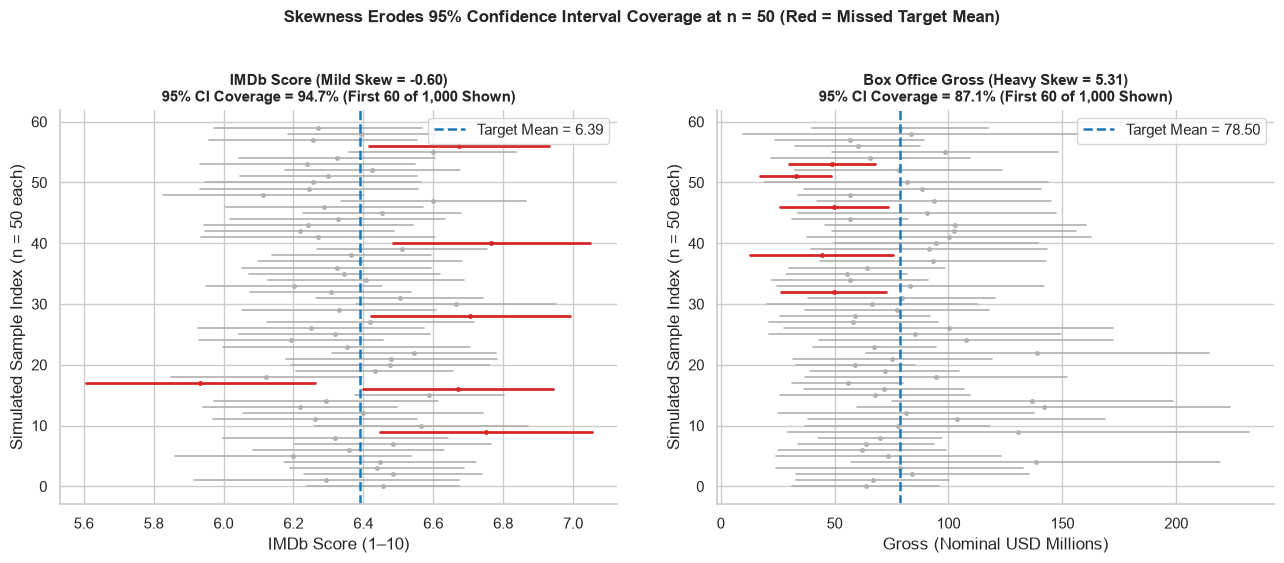

In [4]:
print("=== STEPS 5 & 6: 95% CI COVERAGE SIMULATION ('score' vs. 'gross_m') ===")

# --- ORIGINAL PREDICTION (STEPS 5 & 6 — UNEDITED) ---
# Prediction (Coverage at n = 50):
# 1. For mildly skewed 'score' (skew = -0.60), 95% t-intervals at n = 50 will achieve empirical coverage very close to the nominal 95% target (roughly 94%–96%).
# 2. For heavily right-skewed 'gross_m' (skew = 5.31), empirical coverage at n = 50 will land noticeably BELOW 'score' and below 95% (roughly 88%–92%). When a sample of 50 misses the rare $1B+ blockbusters, both the sample mean and sample SD are underestimated, producing a narrow interval shifted too far left to capture the true dataset mean ($78.50M).

def run_coverage_sim(series, n_samples=1000, sample_size=50, seed=42):
    vals = series.dropna()
    true_mean = float(vals.mean())
    rng_sim = np.random.default_rng(seed)
    hits = 0
    intervals = []
    for _ in range(n_samples):
        samp = rng_sim.choice(vals, size=sample_size, replace=True)
        m = float(samp.mean())
        e = float(samp.std(ddof=1)) / np.sqrt(sample_size)
        lo, hi = stats.t.interval(0.95, df=sample_size - 1, loc=m, scale=e)
        hit = (lo <= true_mean <= hi)
        hits += int(hit)
        intervals.append((float(lo), float(hi), m, hit))
    return hits / n_samples, true_mean, intervals

cov_score, true_mean_score, ints_score = run_coverage_sim(movies['score'], n_samples=1000, sample_size=50, seed=42)
cov_gross, true_mean_gross, ints_gross = run_coverage_sim(movies['gross_m'], n_samples=1000, sample_size=50, seed=42)

cov_summary = pd.DataFrame({
    'variable': ['score (skew = -0.60)', 'gross_m (skew = 5.31)'],
    'bootstrap_target_mean': [round(true_mean_score, 3), round(true_mean_gross, 2)],
    'nominal_target_pct': [95.0, 95.0],
    'empirical_coverage_pct': [round(cov_score * 100, 1), round(cov_gross * 100, 1)],
    'miss_rate_pct': [round((1 - cov_score) * 100, 1), round((1 - cov_gross) * 100, 1)]
})
display(cov_summary)

# Plot the first 60 simulated 95% CIs for both variables so hits (grey) and misses (red) are visually clear
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(13, 5.5))

for ax, int_list, t_mean, cov_val, label_txt, unit_txt in zip(
    (ax_l, ax_r),
    (ints_score[:60], ints_gross[:60]),
    (true_mean_score, true_mean_gross),
    (cov_score * 100, cov_gross * 100),
    ('IMDb Score (Mild Skew = -0.60)', 'Box Office Gross (Heavy Skew = 5.31)'),
    ('IMDb Score (1–10)', 'Gross (Nominal USD Millions)')
):
    for idx_i, (lo, hi, m, hit) in enumerate(int_list):
        clr = '#b0b0b0' if hit else '#d62728'
        lw = 1.2 if hit else 2.0
        ax.plot([lo, hi], [idx_i, idx_i], color=clr, linewidth=lw)
        ax.plot(m, idx_i, 'o', color=clr, markersize=2.5)
    ax.axvline(t_mean, color='#1f77b4', linestyle='--', linewidth=1.8, label=f'Target Mean = {t_mean:.2f}')
    finish(
        ax,
        f'{label_txt}\n95% CI Coverage = {cov_val:.1f}% (First 60 of 1,000 Shown)',
        unit_txt,
        'Simulated Sample Index (n = 50 each)'
    )
    ax.legend(loc='upper right')

fig.suptitle('Skewness Erodes 95% Confidence Interval Coverage at n = 50 (Red = Missed Target Mean)', y=1.02, fontsize=12, fontweight='bold')
fig.tight_layout(w_pad=3.0)
fig.savefig('ci_coverage_score_vs_gross.png', dpi=200)
plt.show()

# Result check (Steps 5 & 6): Both directional predictions held — score (skew = -0.60) achieved 94.7% empirical coverage (miss rate 5.3%, right inside the predicted 94%–96% window), whereas heavily right-skewed gross_m (skew = 5.31) dropped to 87.1% coverage (miss rate 12.9%, just below the predicted 88%–92% range) because samples of n = 50 that miss extreme $1B+ blockbusters underestimate both the sample mean and SD, shifting intervals below the $78.50M target mean.


### Plain-English Confidence Interval Conclusion

* **Rubric Statement:** Average IMDb score is **6.39**, 95 percent CI from **6.37** to **6.41**, `n = 7,665`.
* **Interpretation:** If we repeatedly drew fresh random samples of `7,665` films from the same underlying sampling process and built a 95% confidence interval from each sample, **95% of those intervals** would capture the true mean of that process—not that there is a 95% probability the true mean lies inside this single computed interval.
* **Limitation (Sampling Noise vs. Selection Bias):** The tight **`±0.02`** margin quantifies **sampling noise only** under a random-sampling assumption; because this dataset is a curated IMDb scrape (capturing roughly ~200 major releases per year across 1980–2020, or ~187/year across 41 years, rather than a random draw of all films ever made), a narrow interval still cannot correct for selection bias toward prominent theatrical releases (with the direction of any bias on `score` not established).
